In [15]:
!git clone https://github.com/tungnguyen2505/nhom21_68PM1_medical-insurance-cost-prediction.git
%cd nhom21_68PM1_medical-insurance-cost-prediction/03_SourceCode/notebooks

Cloning into 'nhom21_68PM1_medical-insurance-cost-prediction'...
remote: Enumerating objects: 20, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 20 (delta 1), reused 20 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (20/20), 21.24 KiB | 10.62 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/nhom21_68PM1_medical-insurance-cost-prediction/03_SourceCode/notebooks/nhom21_68PM1_medical-insurance-cost-prediction/03_SourceCode/notebooks/nhom21_68PM1_medical-insurance-cost-prediction/03_SourceCode/notebooks


In [19]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../../data/insurance.csv')
sns.set_theme(style='whitegrid')
print(f"Kích thước dữ liệu: {df.shape}")
df.head()

Kích thước dữ liệu: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



=== Thống kê charges theo biến: smoker ===
        count      mean    median       std
smoker                                     
no       1064   8434.27   7345.41   5993.78
yes       274  32050.23  34456.35  11541.55

=== Thống kê charges theo biến: sex ===
        count      mean   median       std
sex                                       
female    662  12569.58  9412.96  11128.70
male      676  13956.75  9369.62  12971.03

=== Thống kê charges theo biến: region ===
           count      mean    median       std
region                                        
northeast    324  13406.38  10057.65  11255.80
northwest    325  12417.58   8965.80  11072.28
southeast    364  14735.41   9294.13  13971.10
southwest    325  12346.94   8798.59  11557.18


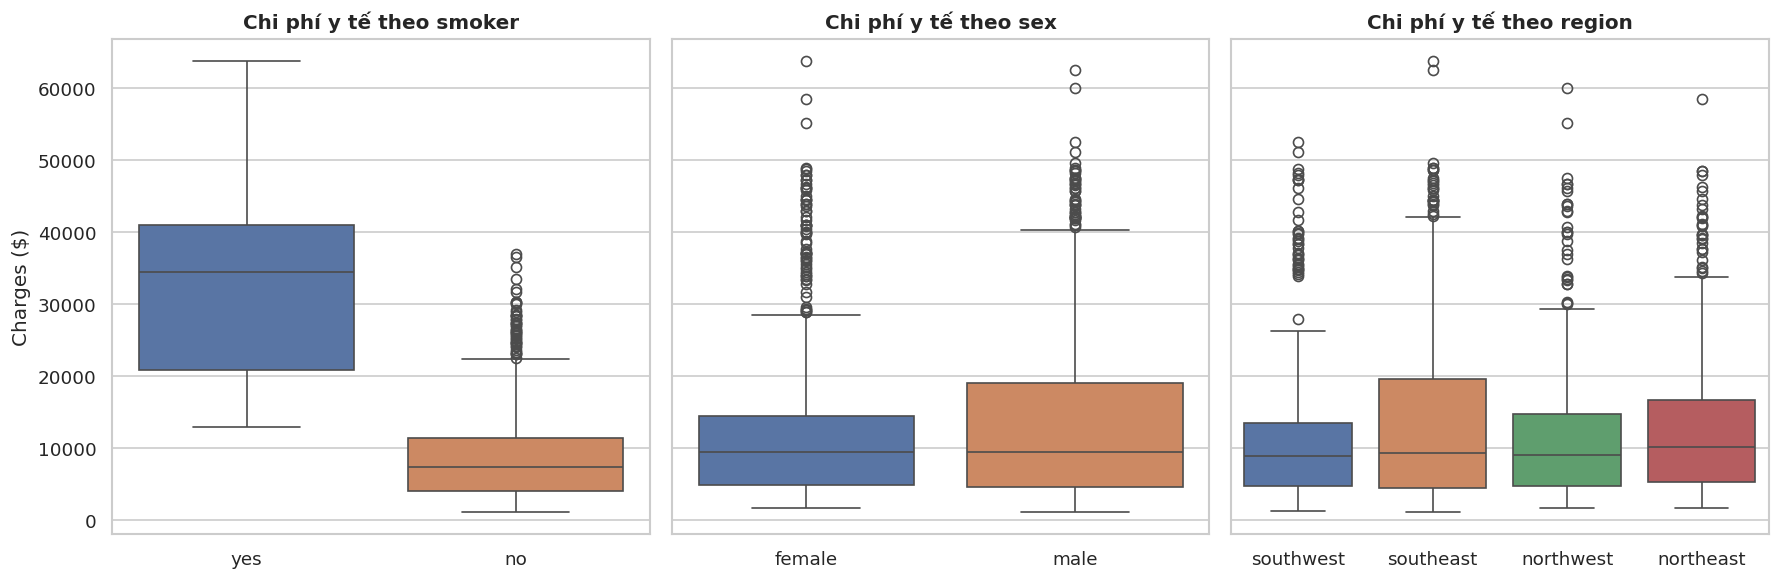

In [21]:
cat_cols = ['smoker', 'sex', 'region']

# 1. Thống kê tần suất và chi phí y tế theo từng nhóm phân loại
for col in cat_cols:
    print(f"\n=== Thống kê charges theo biến: {col} ===")
    summary = df.groupby(col)['charges'].agg(
        count='count',
        mean='mean',
        median='median',
        std='std'
    ).round(2)
    print(summary)

# 2. Vẽ Boxplot so sánh phân phối charges theo từng nhóm
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for i, col in enumerate(cat_cols):
    sns.boxplot(
        data=df, x=col, y='charges',
        hue=col, legend=False, ax=axes[i]
    )
    axes[i].set_title(f'Chi phí y tế theo {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Charges ($)' if i == 0 else '')

plt.tight_layout()
plt.show()

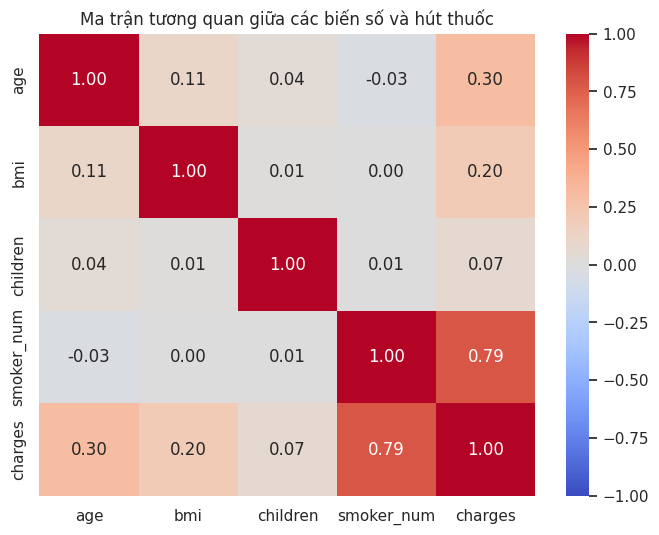

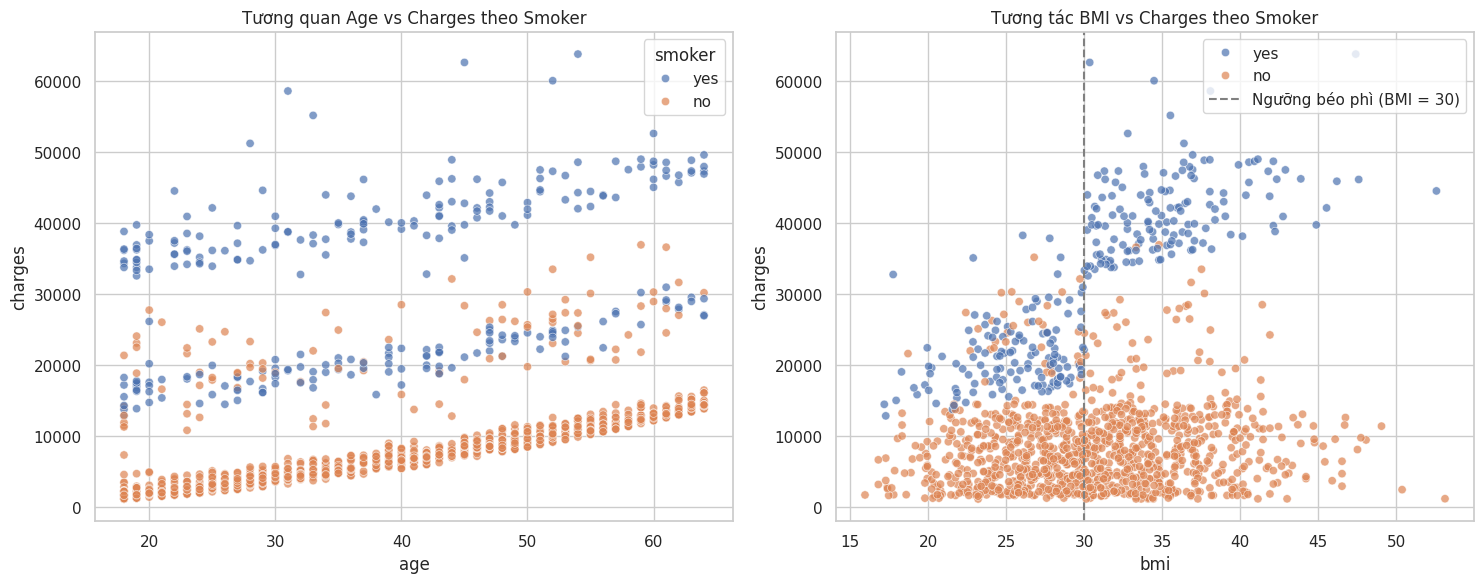

In [ ]:
# 1. Heatmap tương quan (mã hóa tạm smoker để thấy rõ mức độ tương quan với charges)
df_corr = df.copy()
df_corr['smoker_num'] = (df_corr['smoker'] == 'yes').astype(int)
num_cols = ['age', 'bmi', 'children', 'smoker_num', 'charges']

plt.figure(figsize=(8, 6))
sns.heatmap(df_corr[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Ma trận tương quan giữa các biến số và hút thuốc')
plt.show()

# 2. Scatter plot chỉ ra tương tác phi tuyến smoker x bmi và xu hướng theo age
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.7, ax=axes[0])
axes[0].set_title('Tương quan Age vs Charges theo Smoker')

sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7, ax=axes[1])
axes[1].axvline(30, color='gray', linestyle='--', label='Ngưỡng béo phì (BMI = 30)')
axes[1].set_title('Tương tác BMI vs Charges theo Smoker')
axes[1].legend()

plt.tight_layout()
plt.show()

### Nhận xét khám phá biến phân loại và tương tác đặc trưng (T08 & T09)

1. **Tác động của các biến phân loại (`smoker`, `sex`, `region`):**
   - **`smoker` là yếu tố phân hóa mạnh nhất:** Nhóm có hút thuốc (`yes`, chiếm ~20.5%) có mức chi phí y tế trung bình và trung vị cao gấp 3–4 lần so với nhóm không hút thuốc (`no`). Hệ số tương quan tuyến tính giữa `smoker_num` và `charges` đạt mức rất cao ($r \approx 0.79$).
   - **`sex` và `region` ít tạo ra khác biệt:** Phân phối `charges` giữa nam/nữ và giữa 4 khu vực địa lý tương đối đồng đều, trung vị gần tương đương nhau.

2. **Xu hướng theo độ tuổi (`age`) và hiệu ứng tương tác `smoker × bmi`:**
   - **Phân tầng theo độ tuổi:** Chi phí y tế tăng dần theo `age` ($r \approx 0.30$) và tách thành 3 dải tầng song song rõ rệt tương ứng với nhóm không hút thuốc, nhóm hút thuốc có BMI bình thường, và nhóm hút thuốc bị béo phì.
   - **Tương tác phi tuyến `smoker × bmi`:** Ở nhóm không hút thuốc, chỉ số `bmi` tăng hầu như không làm thay đổi `charges`. Ngược lại, ở nhóm có hút thuốc, khi vượt ngưỡng béo phì ($\text{BMI} \ge 30$), chi phí y tế tăng vọt đột biến lên trên $35,000.
   - **Định hướng mô hình hóa:** Mối quan hệ phi tuyến và tương tác mạnh giữa `smoker` và `bmi` là cơ sở để tạo thêm đặc trưng tương tác (`smoker×bmi`, `obese_smoker`) ở bước Feature Engineering và dự báo các mô hình phi tuyến/cây quyết định (Random Forest, Boosting) sẽ vượt trội hơn hồi quy tuyến tính thuần túy.